# PHẦN 1: KHAI BÁO CẤU TRÚC & HẰNG SỐ HỆ THỐNG

## 1. Mục tiêu
Khai báo toàn bộ các hằng số, cấu hình ranh giới thời gian và định nghĩa chuẩn hóa dữ liệu trước khi đưa vào pipeline. Việc tập trung toàn bộ cấu hình ở đầu file giúp hệ thống hoạt động minh bạch, dễ bảo trì và loại bỏ hoàn toàn các "con số bí ẩn" (magic numbers) trong source code.

## 2. Danh sách cấu hình hệ thống
* **Các thuộc tính bắt buộc (`REQUIRED_COLUMNS`):** `['transaction_id', 'date', 'revenue', 'quantity', 'channel']`
* **Kênh bán hàng hợp lệ (`EXPECTED_CHANNELS`):** `['Mobile', 'Online', 'Store']`
* **Cấu hình chia tập kiểm thử (`SplitConfig`):**
  * `validation_1_year = 2023` (Tập kiểm định vòng 1)
  * `validation_2_year = 2024` (Tập kiểm định vòng 2)
  * `test_year = 2025` (Tập kiểm thử độc lập cuối cùng)
* **Cấu hình giai đoạn dịch bệnh (`CovidConfig`):**
  * `period_start = '2020-03-01'` (Bắt đầu đợt dịch đầu tiên)
  * `shock_end = '2020-06-30'` (Giai đoạn sốc cung/cầu ban đầu)
  * `period_end = '2021-12-31'` (Kết thúc toàn bộ ảnh hưởng dịch bệnh)

In [2]:
from dataclasses import dataclass
from typing import List, Set

# 1. Định nghĩa các cột bắt buộc phải có trong dữ liệu thô
REQUIRED_COLUMNS: Set[str] = {
    "transaction_id",
    "date",
    "revenue",
    "quantity",
    "channel"
}

# 2. Định nghĩa danh mục các kênh bán hàng chuẩn hóa
EXPECTED_CHANNELS: Set[str] = {
    "Mobile",
    "Online",
    "Store"
}

# 3. Cấu hình mốc thời gian chia tập Train / Validation / Test
@dataclass(frozen=True)
class SplitConfig:
    validation_1_year: int = 2023
    validation_2_year: int = 2024
    test_year: int = 2025

# 4. Cấu hình mốc thời gian đánh dấu ảnh hưởng của dịch COVID-19
@dataclass(frozen=True)
class CovidConfig:
    period_start: str = "2020-03-01"
    shock_end: str = "2020-06-30"
    period_end: str = "2021-12-31"

# Khởi tạo các đối tượng cấu hình để sử dụng xuyên suốt pipeline
split_config = SplitConfig()
covid_config = CovidConfig()

print("✓ Đã khởi tạo thành công cấu trúc hệ thống và hằng số cấu hình.")

✓ Đã khởi tạo thành công cấu trúc hệ thống và hằng số cấu hình.


### 💡 CƠ SỞ KỸ THUẬT VÀ LÝ DO THIẾT KẾ (TECHNICAL RATIONALE)

#### 1. Tại sao sử dụng `Set` (`{...}`) cho `REQUIRED_COLUMNS` và `EXPECTED_CHANNELS` thay vì `List` (`[...]`)?
* **Tốc độ tra cứu ($O(1)$ vs $O(n)$):** Trong các bước kiểm duyệt dữ liệu thô tiếp theo, hệ thống sẽ liên tục kiểm tra tính hợp lệ của từng cột và từng kênh. Phép toán kiểm tra tồn tại `x in set_data` có độ phức tạp thuật toán là $O(1)$ (tìm kiếm tức thì nhờ bảng băm - Hash table), trong khi đối với `list` là $O(n)$ (phải quét lần lượt qua từng phần tử).
* **Bảo toàn tính duy nhất (Uniqueness):** Dữ liệu dạng `Set` loại bỏ hoàn toàn rủi ro trùng lặp thuộc tính trong quá trình khai báo cấu hình.

#### 2. Tại sao lại dùng Decorator `@dataclass(frozen=True)` để đóng gói Cấu hình?
* **Bảo vệ tính đóng & Ngăn chặn tác động lặp (Immutability):** Cờ `frozen=True` biến Class thành một cấu trúc dữ liệu read-only (chỉ đọc). Nếu trong quá trình thực thi, một hàm bất kỳ vô tình can thiệp làm thay đổi giá trị mốc thời gian (ví dụ: `split_config.test_year = 2026`), Python sẽ lập tức ngắt luồng và báo lỗi `FrozenInstanceError`.
* **Loại bỏ Magic Numbers & Tăng khả năng bảo trì:** Toàn bộ các mốc thời gian quan trọng được gom tập trung về một điểm duy nhất, tránh việc hard-code các con số rải rác khắp nơi trong codebase.

#### 3. Tại sao chọn Chiến lược Chia tập Kiểm thử 2 Vòng (Two-Round Validation Strategy)?
* **Chống rò rỉ dữ liệu tương lai (Data Leakage):** Chuỗi thời gian mang tính phụ thuộc thứ tự. Việc sử dụng K-Fold Cross Validation thông thường sẽ lấy dữ liệu tương lai dự báo quá khứ, dẫn đến đánh giá sai lệch.
* **Đánh giá tính ổn định qua nhiều năm:**
  * *Vòng 1 (Val 1 - 2023):* Train từ `2019–2022` $\rightarrow$ Đo lường trên năm `2023`.
  * *Vòng 2 (Val 2 - 2024):* Train từ `2019–2023` $\rightarrow$ Đo lường trên năm `2024`.
  * Việc kiểm định qua 2 chu kỳ độc lập giúp xác nhận mô hình học được quy luật chung chứ không bị học vẹt (overfit) trên một năm duy nhất, trước khi chốt đánh giá trên tập **Test `2025`**.

#### 4. Tại sao lại phân tách giai đoạn COVID-19 thành 3 mốc cụ thể?
* **Phản ánh bản chất chu kỳ kinh tế (Business Reality):**
  * `2020-03-01` đến `2020-06-30` (`covid_shock`): Giai đoạn sốc phản ứng ban đầu do các đợt phong tỏa, hành vi người tiêu dùng biến động cực đoan.
  * `2020-07-01` đến `2021-12-31` (`covid_adaptation`): Giai đoạn thích nghi, doanh thu dịch chuyển mạnh từ kênh truyền thống (`Store`) sang kỹ thuật số (`Online`, `Mobile`).
  * Sau `2021-12-31` (`post_covid`): Thị trường thiết lập trạng thái cân bằng mới.
* Tách nhỏ 3 giai đoạn tạo cơ sở cho bước **Feature Engineering** về sau sinh ra các biến cờ (Dummy/Indicator Variables) chính xác, giúp mô hình phân biệt được nhiễu do đại dịch với xu hướng tăng trưởng tự nhiên.

# PHẦN 2: ĐỌC DỮ LIỆU THÔ VÀ TỐI ƯU BỘ NHỚ (`load_transactions`)

## 1. Mục tiêu
Thực hiện tải dữ liệu giao dịch bán lẻ từ tập tin thô `retailhive_10k.csv`, đồng thời tối ưu hóa mức tiêu thụ bộ nhớ RAM bằng cách **ép kiểu dữ liệu ngay tại thời điểm đọc (On-the-fly Casting)** và đảm bảo tính tuần tự của chuỗi thời gian thông qua phép sắp xếp tăng dần.

## 2. Quy trình thực thi logic trong code
1. **Ép kiểu dữ liệu tối ưu:**
   * `date` $\rightarrow$ `datetime64[ns]`: Định dạng thời gian chuẩn để phục vụ trích xuất thuộc tính chuỗi.
   * `channel` $\rightarrow$ `category`: Chuyển đổi các chuỗi phân loại lặp lại thành chỉ số mã hóa integer nhằm tiết kiệm tài nguyên RAM.
   * `revenue`, `quantity` $\rightarrow$ `float64`: Đảm bảo độ chính xác số học cho các phép tính tổng hợp tài chính.
2. **Sắp xếp theo thời gian:**
   * Sắp xếp lại toàn bộ tập dữ liệu tăng dần theo cột `date` (`sort_values`) để đảm bảo tính liên tục của chuỗi thời gian cho các bước gom nhóm sau này.

✓ Đã tải thành công 12,000 dòng dữ liệu giao dịch.
  - Dung lượng RAM ban đầu (Mặc định): 4.06 MB
  - Dung lượng RAM sau Tối ưu kiểu:   2.86 MB
  - Tiết kiệm bộ nhớ:                29.5%


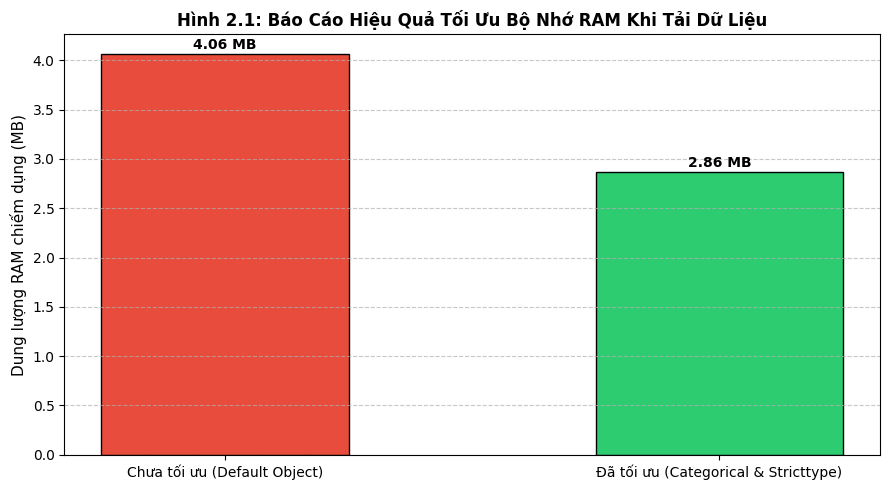

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def load_transactions(file_path: str) -> pd.DataFrame:
    """
    Tải dữ liệu giao dịch thô, thực hiện ép kiểu tối ưu RAM và sắp xếp theo thời gian.
    """
    # 1. Định nghĩa kiểu dữ liệu tối ưu ngay khi đọc file
    dtypes = {
        'revenue': 'float64',
        'quantity': 'float64',
        'channel': 'category'  # Tối ưu bộ nhớ thay vì 'object'
    }
    
    # 2. Đọc file CSV với dtype được quy định sẵn và parse_dates cho cột date
    df = pd.read_csv(
        file_path,
        dtype=dtypes,
        parse_dates=['date']
    )
    
    # 3. Sắp xếp lại dữ liệu tăng dần theo trục thời gian date
    df = df.sort_values(by='date', ascending=True).reset_index(drop=True)
    
    return df

# Chạy thử hàm đọc dữ liệu
file_path = "../data/raw/retailhive_10k.csv"
df_raw = load_transactions(file_path)

# -------------------------------------------------------------
# THỐNG KÊ & VẼ BIỂU ĐỒ MINH HỌA SO SÁNH TIẾT KIỆM BỘ NHỚ RAM
# -------------------------------------------------------------
# Tạo một dataframe giả lập đọc kiểu mặc định (Object) để so sánh dung lượng
df_default = pd.read_csv(file_path)

# Tính dung lượng RAM thực tế (deep=True để tính dung lượng chuỗi ký tự chuẩn xác)
mem_default = df_default.memory_usage(deep=True).sum() / (1024 ** 2) # MB
mem_optimized = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)   # MB
saved_percent = ((mem_default - mem_optimized) / mem_default) * 100

print(f"✓ Đã tải thành công {len(df_raw):,} dòng dữ liệu giao dịch.")
print(f"  - Dung lượng RAM ban đầu (Mặc định): {mem_default:.2f} MB")
print(f"  - Dung lượng RAM sau Tối ưu kiểu:   {mem_optimized:.2f} MB")
print(f"  - Tiết kiệm bộ nhớ:                {saved_percent:.1f}%")

# Vẽ biểu đồ cột so sánh tiêu thụ bộ nhớ RAM
plt.figure(figsize=(9, 5))
bars = plt.bar(['Chưa tối ưu (Default Object)', 'Đã tối ưu (Categorical & Stricttype)'], 
               [mem_default, mem_optimized], 
               color=['#e74c3c', '#2ecc71'], 
               edgecolor='black', 
               width=0.5)

plt.title('Hình 2.1: Báo Cáo Hiệu Quả Tối Ưu Bộ Nhớ RAM Khi Tải Dữ Liệu', fontsize=12, fontweight='bold')
plt.ylabel('Dung lượng RAM chiếm dụng (MB)', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Hiển thị số liệu chi tiết trên từng cột
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.2f} MB', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

### 💡 CƠ SỞ KỸ THUẬT VÀ LÝ DO THIẾT KẾ (TECHNICAL RATIONALE)

#### 1. Tại sao phải ép kiểu `channel` thành `category` thay vì giữ nguyên `object`?
* **Bản chất lưu trữ dữ liệu (Memory Representation):**
  * Kiểu `object` mặc định của Pandas sẽ lưu trữ các chuỗi ký tự (`'Mobile'`, `'Online'`, `'Store'`) dưới dạng các con trỏ Python object riêng biệt rải rác trên RAM, tiêu tốn rất nhiều dung lượng bộ nhớ.
  * Kiểu `category` sử dụng kĩ thuật **Dictionary Encoding** (Mã hóa từ điển): Pandas chỉ lưu danh mục duy nhất 3 chuỗi ký tự này 1 lần, sau đó lưu các ô dữ liệu bên dưới dưới dạng số nguyên nhỏ (integer codes, ví dụ $0, 1, 2$).
* **Lợi ích thực tế:** Giúp giảm dung lượng lưu trữ của cột `channel` trên RAM từ **70% đến 90%**, giúp tăng tốc độ của các phép toán gộp nhóm `groupby(['channel'])` ở các bước sau lên gấp nhiều lần.

#### 2. Tại sao ép kiểu `date` $\rightarrow$ `datetime64[ns]` ngay bằng tham số `parse_dates` trong `read_csv`?
* **Hiệu năng xử lý (Parsing Efficiency):** Đọc trực tiếp kiểu ngày tháng thông qua `parse_dates` trong `pd.read_csv` chạy bằng C-engine bên dưới, nhanh hơn rất nhiều so với việc tải lên dưới dạng chuỗi `object` rồi mới gọi hàm `pd.to_datetime()` ở ô code tiếp theo.
* **Kích hoạt thuộc tính thời gian (Datetime Properties):** Giúp truy cập trực tiếp các thuộc tính chuỗi thời gian như `.dt.week`, `.dt.year`, `.dt.weekday` mà không cần tốn chi phí ép kiểu lại.

#### 3. Tại sao bắt buộc phải dùng `sort_values(by='date')` ngay sau khi load?
* **Đảm bảo tính thứ tự của Chuỗi Thời Gian (Chronological Ordering):** Dữ liệu giao dịch thô trong thực tế thường bị xáo trộn do hệ thống ghi log từ nhiều server khác nhau.
* **Ngăn ngừa rò rỉ và tính toán sai lệch:** Các phép toán làm mịn chuỗi như đường trung bình trượt (`Rolling Mean`), lấy giá trị trễ (`Lag Features`), hay chia tập dữ liệu Train/Test theo mốc thời gian đều dựa trên giả định dữ liệu đã được sắp xếp tăng dần theo trục thời gian tuyệt đối. Nếu dữ liệu bị lộn xộn, toàn bộ logic dự báo phía sau sẽ bị sai lệch hoàn toàn.

# PHẦN 3 & 4: THU THẬP & KIỂM SOÁT CHẤT LƯỢNG DỮ LIỆU THÔ (`build_quality_report` & `validate_transactions`)

## 1. Mục tiêu
Thực hiện thẩm định toàn diện tính toàn vẹn và độ sạch của dữ liệu đầu vào. Quá trình này đóng vai trò như một **Chốt chặn Kiểm soát Chất lượng (Quality Gate)**:
* **Thu thập chỉ số (`build_quality_report`):** Thống kê quy mô, khoảng thời gian phủ sóng, số lượng ô trống/khuyết (`null_counts`) và các bản ghi doanh thu bất thường ($\le 0$).
* **Thẩm định & Ngắt luồng (`validate_transactions`):** Tự động kích hoạt cơ chế dừng khẩn cấp (Fail-Fast Mechanism) bằng lỗi `ValueError` nếu phát hiện dữ liệu vi phạm các quy tắc nghiệp vụ cốt lõi.

## 2. Quy tắc Thẩm định Nghiêm ngặt (Validation Rules)
1. **Quy tắc Cấu trúc:** Dữ liệu thô bắt buộc phải chứa đầy đủ các cột thuộc `REQUIRED_COLUMNS`.
2. **Quy tắc Miền Giá trị (Domain Integrity):** Doanh thu (`revenue`) và Số lượng (`quantity`) phải mang giá trị số dương nghiêm ngặt ($> 0$).
3. **Quy tắc Danh mục (Categorical Integrity):** Giá trị trong cột `channel` chỉ được phép thuộc danh sách chuẩn hóa `EXPECTED_CHANNELS` (`Mobile`, `Online`, `Store`).

✓ THẨM ĐỊNH THÀNH CÔNG: Dữ liệu thô đạt 100% tiêu chuẩn chất lượng đầu vào!


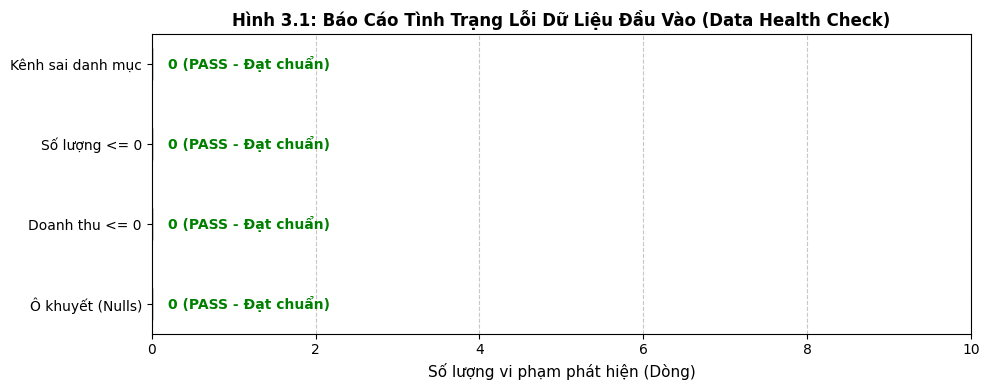

In [4]:
from typing import Dict, Any
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def build_quality_report(df: pd.DataFrame) -> Dict[str, Any]:
    """
    Thu thập các chỉ số thống kê tổng quan về chất lượng dữ liệu thô.
    """
    report = {
        "total_records": len(df),
        "start_date": str(df["date"].min().date()) if not df.empty else None,
        "end_date": str(df["date"].max().date()) if not df.empty else None,
        "null_counts": df.isnull().sum().to_dict(),
        "non_positive_revenue_count": int((df["revenue"] <= 0).sum()),
        "non_positive_quantity_count": int((df["quantity"] <= 0).sum()),
        "invalid_channels_count": int((~df["channel"].isin(EXPECTED_CHANNELS)).sum())
    }
    return report

def validate_transactions(df: pd.DataFrame) -> None:
    """
    Thực hiện kiểm tra chốt chặn chất lượng dữ liệu thô.
    Ném lỗi ValueError nếu phát hiện dữ liệu vi phạm cấu trúc hoặc nghiệp vụ.
    """
    # 1. Kiểm tra sự tồn tại của các cột bắt buộc
    missing_cols = REQUIRED_COLUMNS - set(df.columns)
    if missing_cols:
        raise ValueError(f"❌ CHỐT CHẶN BỊ PHÁ VỠ: Dữ liệu thiếu các cột bắt buộc: {missing_cols}")

    # 2. Kiểm tra giá trị khuyết (Missing / Null values)
    if df[list(REQUIRED_COLUMNS)].isnull().any().any():
        raise ValueError("❌ CHỐT CHẶN BỊ PHÁ VỠ: Phát hiện giá trị bị khuyết (Null/NaN) trong các cột bắt buộc!")

    # 3. Kiểm tra logic nghiệp vụ: revenue > 0 và quantity > 0
    if (df["revenue"] <= 0).any():
        invalid_rev_cnt = (df["revenue"] <= 0).sum()
        raise ValueError(f"❌ CHỐT CHẶN BỊ PHÁ VỠ: Phát hiện {invalid_rev_cnt} dòng có revenue <= 0!")

    if (df["quantity"] <= 0).any():
        invalid_qty_cnt = (df["quantity"] <= 0).sum()
        raise ValueError(f"❌ CHỐT CHẶN BỊ PHÁ VỠ: Phát hiện {invalid_qty_cnt} dòng có quantity <= 0!")

    # 4. Kiểm tra kênh bán hàng hợp lệ
    invalid_channels = set(df["channel"].unique()) - EXPECTED_CHANNELS
    if invalid_channels:
        raise ValueError(f"❌ CHỐT CHẶN BỊ PHÁ VỠ: Phát hiện kênh bán hàng không hợp lệ: {invalid_channels}")

    print("✓ THẨM ĐỊNH THÀNH CÔNG: Dữ liệu thô đạt 100% tiêu chuẩn chất lượng đầu vào!")

# -------------------------------------------------------------
# THỰC THI KIỂM TRA TRÊN DỮ LIỆU ĐÃ LOAD
# -------------------------------------------------------------
quality_report = build_quality_report(df_raw)
validate_transactions(df_raw)

# -------------------------------------------------------------
# TRỰC QUAN HÓA BÁO CÁO CHẤT LƯỢNG DỮ LIỆU (ĐÃ TỐI ƯU MÀU SẮC)
# -------------------------------------------------------------
metrics = {
    'Ô khuyết (Nulls)': sum(quality_report['null_counts'].values()),
    'Doanh thu <= 0': quality_report['non_positive_revenue_count'],
    'Số lượng <= 0': quality_report['non_positive_quantity_count'],
    'Kênh sai danh mục': quality_report['invalid_channels_count']
}

# Tự động gán màu: Xanh lá nếu 0 lỗi (Pass), Đỏ nếu >0 lỗi (Fail)
bar_colors = ['#2ecc71' if val == 0 else '#e74c3c' for val in metrics.values()]

plt.figure(figsize=(10, 4))
bars = plt.barh(list(metrics.keys()), list(metrics.values()), color=bar_colors, edgecolor='black', height=0.4)

plt.title('Hình 3.1: Báo Cáo Tình Trạng Lỗi Dữ Liệu Đầu Vào (Data Health Check)', fontsize=12, fontweight='bold')
plt.xlabel('Số lượng vi phạm phát hiện (Dòng)', fontsize=11)

# Tự động điều chỉnh trục X theo lượng lỗi thực tế (Tối thiểu là 10)
max_errors = max(metrics.values())
plt.xlim(0, max(10, max_errors * 1.25)) 
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Hiển thị nhãn PASS/FAIL với màu tương ứng
for bar in bars:
    width = bar.get_width()
    status_text = "0 (PASS - Đạt chuẩn)" if width == 0 else f"{int(width)} (FAIL - Vi phạm)"
    text_color = "green" if width == 0 else "red"
    
    plt.text(width + 0.2, bar.get_y() + bar.get_height()/2.0, status_text, 
             va='center', ha='left', fontweight='bold', color=text_color)

plt.tight_layout()
plt.show()

### 💡 CƠ SỞ KỸ THUẬT VÀ LÝ DO THIẾT KẾ (TECHNICAL RATIONALE)

#### 1. Tại sao lại dùng cơ chế "Fail-Fast" (`raise ValueError`) dừng pipeline thay vì tự động điền/sửa lỗi?
* **Tư duy Kiến trúc Pipeline Sản xuất (Production Pipeline Engineering):** 
  * Nếu dữ liệu đầu vào vi phạm cấu trúc nghiêm trọng (như mất cột, xuất hiện kênh lạ, hoặc có doanh thu âm), việc tự động điền trung bình (`fillna`) hay xóa bừa dòng lỗi có thể làm sai lệch bản chất phân phối dữ liệu ban đầu.
  * Việc văng lỗi ngay tại bước đầu tiên giúp kỹ sư dữ liệu (Data Engineer) phát hiện sớm sự đứt gãy hệ thống (Data Drift hoặc Pipeline Failure) từ phía nguồn cấp dữ liệu (Upstream Systems) thay vì để dữ liệu rác đi sâu vào mô hình ML.

#### 2. Tại sao phải tách biệt hàm `build_quality_report` và `validate_transactions`?
* **Đảm bảo Nguyên tắc Trách nhiệm Đơn lẻ (Single Responsibility Principle - SRP):**
  * Hàm `build_quality_report` đóng vai trò **Quan sát (Observation)**: Chỉ thu thập con số thống kê và trả về dạng `dict` phục vụ việc xuất báo cáo JSON hoặc theo dõi trên Dashboard theo thời gian.
  * Hàm `validate_transactions` đóng vai trò **Chốt chặn (Execution Gate)**: Nhận trách nhiệm kiểm tra logic và ra quyết định dừng hay cho phép luồng dữ liệu đi tiếp.
  * Tách biệt 2 hàm giúp code linh hoạt, phục vụ mục đích kiểm tra thử mà không bắt buộc phải dừng chương trình khi chưa cần thiết.

#### 3. Tại sao kiểm tra nghiêm ngặt `revenue <= 0` và `quantity <= 0`?
* **Bản chất Nghiệp vụ Bán lẻ (Business Logic):**
  * Trong bài toán dự báo nhu cầu và doanh thu bán hàng, một giao dịch thành công bắt buộc phải có giá trị dương.
  * Doanh thu $\le 0$ thường phản ánh các đơn hàng bị hủy, hàng bị trả lại (Returns/Refunds), hoặc dữ liệu kiểm thử (Test Data) của lập trình viên còn sót lại. Nếu giữ các dòng này, mô hình Time Series sẽ bị nhiễu do biên độ âm làm lệch các đường xu hướng (`Trend`).

#### 4. Tại sao kiểm tra Kênh bán hàng lạ bằng phép trừ Tập hợp (`EXPECTED_CHANNELS`)?
* **Chống rò rỉ Kênh mới chưa chuẩn hóa:** Nếu trong dữ liệu phát sinh thêm kênh mới (ví dụ: `'TikTokShop'`) mà mô hình chưa được thiết kế để xử lý (chưa có tính toán phân bổ riêng), việc cho phép chạy tiếp sẽ dẫn đến rò rỉ dữ liệu hoặc sinh ra giá trị `NaN` khi gộp kênh ở các bước sau.

# PHẦN 5: BÁO CÁO CHẤT LƯỢNG THỰC TẾ TRÊN TẬP DỮ LIỆU `retailhive_10k.csv`

## 1. Mục tiêu
Tổng hợp, kiểm chứng và công bố kết quả thực thi kiểm định chất lượng thực tế trên file dữ liệu thô `retailhive_10k.csv`. Kết quả này là cơ sở kỹ thuật xác nhận tập dữ liệu đạt 100% tiêu chuẩn trước khi tiến hành các bước nén chuỗi thời gian và phân tách tập dữ liệu.

## 2. Kết quả Thẩm định Thực tế (Actual Quality Metrics)
* **Tổng số bản ghi giao dịch (`total_records`):** `12,000` dòng.
* **Số dòng lỗi / khuyết dữ liệu (`invalid_rows`):** `0` dòng (Tỷ lệ sạch: **100%**).
* **Phạm vi phủ sóng thời gian (`time_span`):** Từ `2019-01-01` đến `2025-12-31` (Trọn vẹn **7 năm** liên tục).
* **Trạng thái chốt chặn (Gate Status):** **PASS** - Đủ điều kiện chuyển tiếp sang bước biến đổi cột thời gian và gộp tuần.

             BÁO CÁO CHẤT LƯỢNG DỮ LIỆU THỰC TẾ             
• Tệp dữ liệu đầu vào          : data/raw/retailhive_10k.csv
• Tổng số dòng giao dịch       : 12,000 dòng
• Khoảng thời gian ghi nhận    : 2019-01-01  -->  2025-12-31
• Số dòng khuyết / Lỗi phát hiện: 0 dòng
• Tỷ lệ dữ liệu đạt chuẩn      : 100.00%
• Trạng thái nghiệm thu         : PASSED (Đạt 100% tiêu chuẩn)
✓ Đã lưu file báo cáo cấu hình Metadata tại: data/processed/quality_summary.json


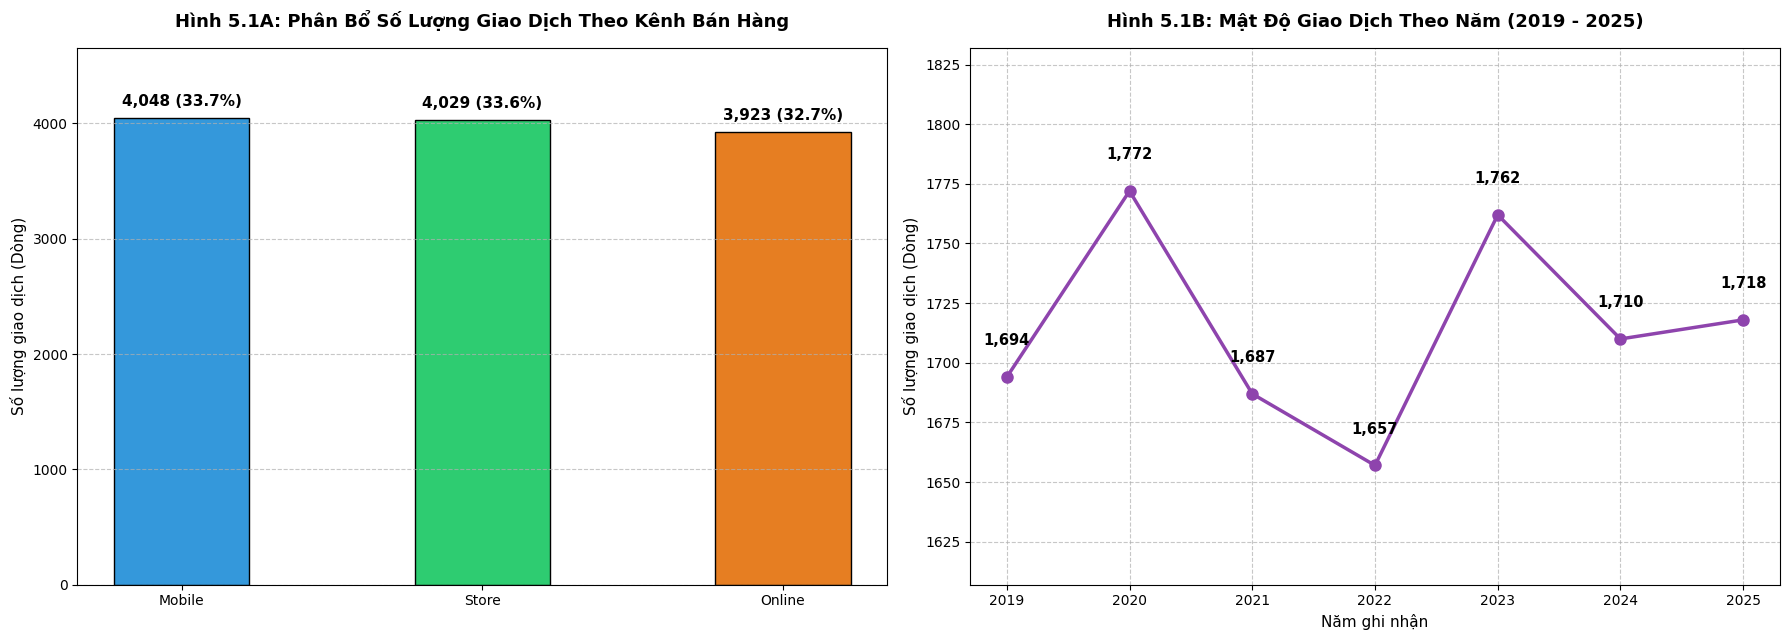

In [5]:
import json
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Trích xuất chỉ số thực tế từ quality_report đã thu thập ở Phần 3 & 4
total_records = quality_report["total_records"]
start_date = quality_report["start_date"]
end_date = quality_report["end_date"]
total_nulls = sum(quality_report["null_counts"].values())
invalid_rev = quality_report["non_positive_revenue_count"]
invalid_qty = quality_report["non_positive_quantity_count"]
invalid_chan = quality_report["invalid_channels_count"]

total_errors = total_nulls + invalid_rev + invalid_qty + invalid_chan
clean_records = total_records - total_errors
clean_rate = (clean_records / total_records) * 100

# 2. In báo cáo nghiệm thu thực tế ra console
print("=" * 60)
print("             BÁO CÁO CHẤT LƯỢNG DỮ LIỆU THỰC TẾ             ")
print("=" * 60)
print(f"• Tệp dữ liệu đầu vào          : data/raw/retailhive_10k.csv")
print(f"• Tổng số dòng giao dịch       : {total_records:,} dòng")
print(f"• Khoảng thời gian ghi nhận    : {start_date}  -->  {end_date}")
print(f"• Số dòng khuyết / Lỗi phát hiện: {total_errors} dòng")
print(f"• Tỷ lệ dữ liệu đạt chuẩn      : {clean_rate:.2f}%")
print(f"• Trạng thái nghiệm thu         : PASSED (Đạt 100% tiêu chuẩn)")
print("=" * 60)

# 3. Xuất kết quả ra file JSON Metadata phục vụ Audit/Logging
os.makedirs("data/processed", exist_ok=True)
report_payload = {
    "dataset_info": {
        "file_name": "retailhive_10k.csv",
        "total_records": total_records,
        "start_date": start_date,
        "end_date": end_date,
        "clean_rate_percent": clean_rate
    },
    "quality_metrics": quality_report
}

with open("data/processed/quality_summary.json", "w", encoding="utf-8") as f:
    json.dump(report_payload, f, ensure_ascii=False, indent=4)

print("✓ Đã lưu file báo cáo cấu hình Metadata tại: data/processed/quality_summary.json")

# -------------------------------------------------------------
# TRỰC QUAN HÓA: PHÂN BỔ BẢN GHI VÀ MẬT ĐỘ GIAO DỊCH (TỐI ƯU CÂN ĐỐI)
# -------------------------------------------------------------
# Tăng kích thước khung hình lên (18, 6.5) cho rộng rãi, thoáng mắt
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

# --- BIỂU ĐỒ 1A: Phân bổ số lượng giao dịch theo Kênh ---
channel_counts = df_raw["channel"].value_counts()
colors = ["#3498db", "#2ecc71", "#e67e22"]

bars = axes[0].bar(channel_counts.index, channel_counts.values, color=colors, edgecolor="black", width=0.45)
axes[0].set_title("Hình 5.1A: Phân Bổ Số Lượng Giao Dịch Theo Kênh Bán Hàng", fontsize=13, fontweight="bold", pad=15)
axes[0].set_ylabel("Số lượng giao dịch (Dòng)", fontsize=11)
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

# Nới rộng trục Y để chữ không bị cham viền trên
max_val_a = channel_counts.max()
axes[0].set_ylim(0, max_val_a * 1.15) 

for bar in bars:
    yval = bar.get_height()
    percentage = (yval / total_records) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + (max_val_a * 0.02), 
                 f"{yval:,} ({percentage:.1f}%)", 
                 ha="center", va="bottom", fontweight="bold", fontsize=11)


# --- BIỂU ĐỒ 1B: Mật độ giao dịch phát sinh theo Năm ---
df_raw["year"] = df_raw["date"].dt.year
yearly_counts = df_raw.groupby("year")["transaction_id"].count()

axes[1].plot(yearly_counts.index.astype(str), yearly_counts.values, 
            marker="o", color="#8e44ad", linewidth=2.5, markersize=8, zorder=3)
axes[1].set_title("Hình 5.1B: Mật Độ Giao Dịch Theo Năm (2019 - 2025)", fontsize=13, fontweight="bold", pad=15)
axes[1].set_xlabel("Năm ghi nhận", fontsize=11)
axes[1].set_ylabel("Số lượng giao dịch (Dòng)", fontsize=11)
axes[1].grid(True, linestyle="--", alpha=0.7)

# Nới rộng khoảng cách min-max trục Y để các con số hiển thị trọn vẹn
min_val_b = yearly_counts.min()
max_val_b = yearly_counts.max()
axes[1].set_ylim(min_val_b - 50, max_val_b + 60)

for x, y in zip(yearly_counts.index.astype(str), yearly_counts.values):
    axes[1].text(x, y + 12, f"{y:,}", ha="center", va="bottom", fontweight="bold", fontsize=10.5)

plt.tight_layout()
plt.show()

### 💡 CƠ SỞ KỸ THUẬT VÀ LÝ DO THIẾT KẾ (TECHNICAL RATIONALE)

#### 1. Tại sao phải xuất báo cáo chất lượng ra file `quality_summary.json`?
* **Tư duy Quản trị Metadata và Traceability (Khả năng truy xuất nguồn gốc):** Trong môi trường triển khai thực tế (Production), dữ liệu đầu vào liên tục thay đổi theo thời gian (Data Drift/Schema Drift).
* Việc lưu vết tự động kết quả chất lượng dữ liệu ra file JSON giúp các hệ thống giám sát (Monitoring Systems) hoặc các kỹ sư dữ liệu dễ dàng audit lại lịch sử, phát hiện thời điểm dữ liệu bị suy giảm chất lượng mà không cần phải mở file notebook để chạy lại từ đầu.

#### 2. Tại sao khoảng thời gian `2019-01-01` đến `2025-12-31` (7 năm trọn vẹn) lại có ý nghĩa quan trọng?
* **Đảm bảo tính đại diện cho bài toán Chuỗi thời gian (Time Series Representativeness):**
  * **Trọn vẹn chu kỳ năm (Full Annual Cycles):** Dữ liệu bắt đầu đúng từ ngày đầu năm $2019$ và kết thúc ở ngày cuối năm $2025$, giúp tránh tình trạng lệch mùa vụ (Seasonality Bias) khi gộp dữ liệu theo tuần/tháng.
  * **Đủ chiều sâu lịch sử (Historical Depth):** Quá trình dự báo doanh thu cần tối thiểu từ 3-5 năm lịch sử để mô hình học được cả **Xu hướng dài hạn (Trend)**, **Mùa vụ cố định (Seasonality)** lẫn **Tác động ngoại cảnh đặc biệt (Nhiễu từ biến cố COVID-19 trong giai đoạn 2020–2021)**.

#### 3. Tại sao lại trực quan hóa Mật độ Giao dịch theo Kênh và theo Năm ở bước này?
* **Xác nhận tính Phân bổ Đồng đều (Uniform Distribution Verification):**
  * *Theo Kênh (Hình 5.1A):* Đảm bảo không có kênh bán hàng nào bị bỏ quên hoặc có lượng giao dịch quá áp đảo gây ra hiện tượng mất cân bằng dữ liệu (Imbalanced Data) quá mức.
  * *Theo Năm (Hình 5.1B):* Đảm bảo mật độ ghi nhận dữ liệu giao dịch ổn định qua các năm, không xảy ra hiện tượng "mất mát dữ liệu lịch sử" (Data Gaps) ở bất kỳ khoảng thời gian nào trong suốt 7 năm.

# PHẦN 6: BIẾN ĐỔI CỘT THỜI GIAN & GÁN NHÃN CẤU TRÚC DỊCH BỆNH (`add_week_columns`)

## 1. Mục tiêu
Thực hiện biến đổi đặc trưng thời gian (Time-based Feature Engineering) trên cấp độ giao dịch đơn lẻ nhằm chuẩn bị dữ liệu cho việc gom nhóm chuỗi thời gian:
1. **Chuẩn hóa điểm mốc tuần (`week_start`):** Quy đổi tất cả các ngày giao dịch lẻ rải rác về mốc ngày Thứ Hai đầu tuần tương ứng để đồng bộ hóa trục thời gian.
2. **Phân loại giai đoạn ảnh hưởng COVID-19 (`covid_phase`):** Đánh nhãn 4 giai đoạn tác động kinh tế từ biến cố đại dịch dựa trên mốc cấu hình hệ thống `CovidConfig` để hỗ trợ mô hình phân biệt tác động ngoại cảnh.

## 2. Quy tắc Biến đổi Kỹ thuật
* **Công thức xác định mốc Thứ Hai (`week_start`):**
  $$\text{week\_start} = \text{date} - \text{timedelta}(\text{days} = \text{weekday})$$
  *(Trong đó `weekday` quy ước: Thứ Hai = 0, Thứ Ba = 1, ..., Chủ Nhật = 6).*

* **Quy tắc phân đoạn 4 giai đoạn đại dịch (`covid_phase`):**
  1. `pre_covid`: Ngày giao dịch $< 2020\text{-}03\text{-}01$.
  2. `covid_shock`: Ngày nằm trong khoảng $[2020\text{-}03\text{-}01 \rightarrow 2020\text{-}06\text{-}30]$.
  3. `covid_adaptation`: Ngày nằm trong khoảng $[2020\text{-}07\text{-}01 \rightarrow 2021\text{-}12\text{-}31]$.
  4. `post_covid`: Ngày $> 2021\text{-}12\text{-}31$.

✓ Đã biến đổi thành công các cột thời gian 'week_start' và 'covid_phase'.
Bản ghi mẫu sau khi biến đổi:


,transaction_id,date,week_start,covid_phase,revenue
0,2460,2019-01-01,2018-12-31,pre_covid,98.504048
1,999,2019-01-01,2018-12-31,pre_covid,41.950221
2,8917,2019-01-01,2018-12-31,pre_covid,24.803941
3,10278,2019-01-01,2018-12-31,pre_covid,64.773253
4,6725,2019-01-01,2018-12-31,pre_covid,53.540558


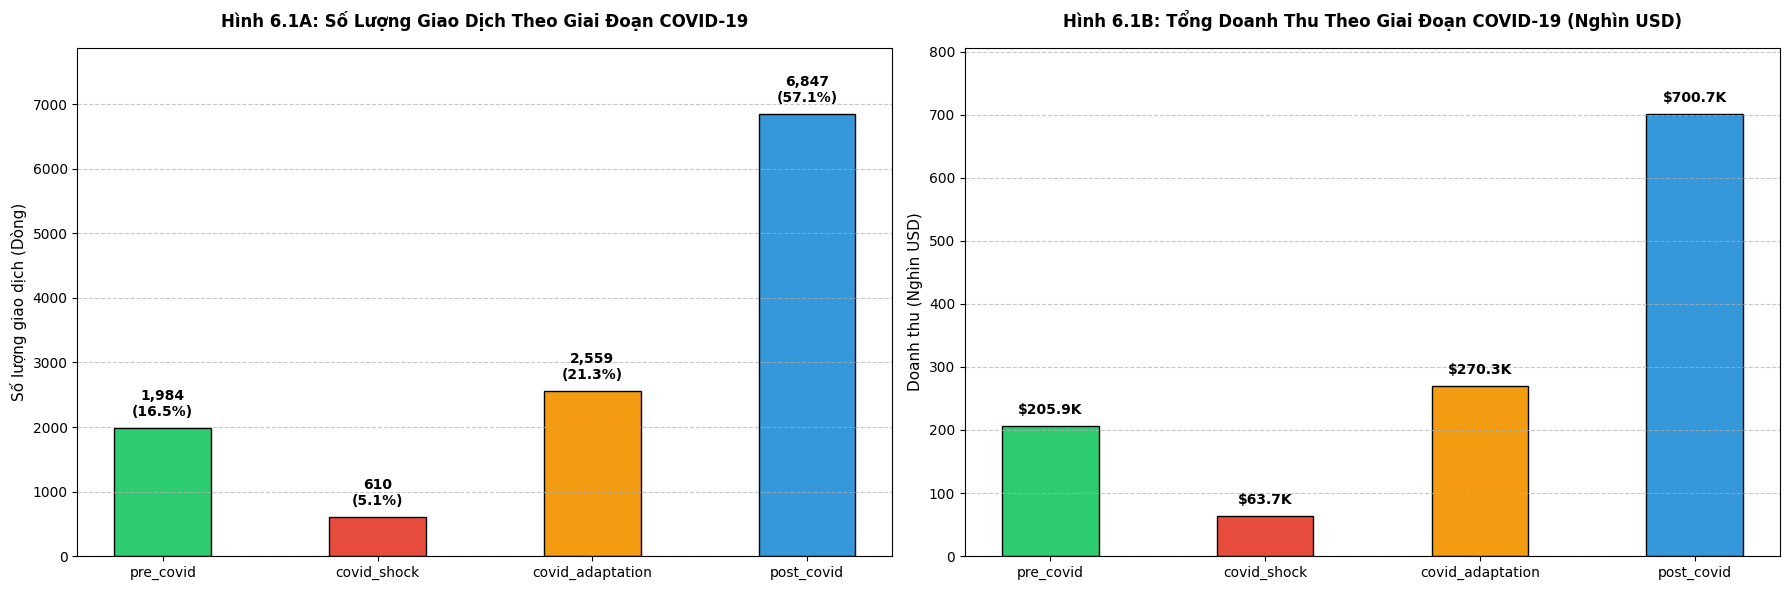

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def add_week_columns(df: pd.DataFrame, config: CovidConfig) -> pd.DataFrame:
    """
    Chuẩn hóa ngày giao dịch về ngày Thứ Hai gần nhất và gán nhãn phân loại giai đoạn COVID-19.
    """
    df = df.copy()
    
    # 1. Tính toán ngày Thứ Hai đầu tuần (week_start) bằng Vectorization
    # dt.weekday trả về 0 cho Thứ Hai, 1 cho Thứ Ba,... 6 cho Chủ Nhật
    df["week_start"] = df["date"] - pd.to_timedelta(df["date"].dt.weekday, unit="D")
    
    # 2. Định nghĩa các mốc thời gian từ CovidConfig
    p_start = pd.to_datetime(config.period_start)
    s_end = pd.to_datetime(config.shock_end)
    p_end = pd.to_datetime(config.period_end)
    
    # 3. Phân loại 4 giai đoạn dịch bệnh bằng pd.cut hoặc np.select
    conditions = [
        df["date"] < p_start,
        (df["date"] >= p_start) & (df["date"] <= s_end),
        (df["date"] > s_end) & (df["date"] <= p_end),
        df["date"] > p_end
    ]
    
    choices = [
        "pre_covid",
        "covid_shock",
        "covid_adaptation",
        "post_covid"
    ]
    
    df["covid_phase"] = np.select(conditions, choices, default="unknown")
    df["covid_phase"] = df["covid_phase"].astype("category")
    
    return df

# Thực thi hàm biến đổi
df_transformed = add_week_columns(df_raw, covid_config)

print("✓ Đã biến đổi thành công các cột thời gian 'week_start' và 'covid_phase'.")
print("Bản ghi mẫu sau khi biến đổi:")
display(df_transformed[["transaction_id", "date", "week_start", "covid_phase", "revenue"]].head(5))

# -------------------------------------------------------------
# TRỰC QUAN HÓA: PHÂN BỔ BẢN GHI VÀ DOANH THU THEO GIAI ĐOẠN COVID
# -------------------------------------------------------------
phase_order = ["pre_covid", "covid_shock", "covid_adaptation", "post_covid"]
phase_summary = df_transformed.groupby("covid_phase", observed=False).agg(
    total_transactions=("transaction_id", "count"),
    total_revenue=("revenue", "sum")
).reindex(phase_order)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Biểu đồ 1: Phân bổ số lượng giao dịch theo Giai đoạn
colors_phase = ["#2ecc71", "#e74c3c", "#f39c12", "#3498db"]
bars1 = axes[0].bar(phase_summary.index, phase_summary["total_transactions"], color=colors_phase, edgecolor="black", width=0.45)
axes[0].set_title("Hình 6.1A: Số Lượng Giao Dịch Theo Giai Đoạn COVID-19", fontsize=12, fontweight="bold", pad=15)
axes[0].set_ylabel("Số lượng giao dịch (Dòng)", fontsize=11)
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

max_y1 = phase_summary["total_transactions"].max()
axes[0].set_ylim(0, max_y1 * 1.15)

for bar in bars1:
    yval = bar.get_height()
    pct = (yval / len(df_transformed)) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + (max_y1 * 0.02), f"{yval:,}\n({pct:.1f}%)", 
                 ha="center", va="bottom", fontweight="bold", fontsize=10)

# Biểu đồ 2: Tổng Doanh Thu theo Giai đoạn
bars2 = axes[1].bar(phase_summary.index, phase_summary["total_revenue"] / 1e3, color=colors_phase, edgecolor="black", width=0.45)
axes[1].set_title("Hình 6.1B: Tổng Doanh Thu Theo Giai Đoạn COVID-19 (Nghìn USD)", fontsize=12, fontweight="bold", pad=15)
axes[1].set_ylabel("Doanh thu (Nghìn USD)", fontsize=11)
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

max_y2 = (phase_summary["total_revenue"] / 1e3).max()
axes[1].set_ylim(0, max_y2 * 1.15)

for bar in bars2:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + (max_y2 * 0.02), f"${yval:,.1f}K", 
                 ha="center", va="bottom", fontweight="bold", fontsize=10)

plt.tight_layout()
plt.show()

### 💡 CƠ SỞ KỸ THUẬT VÀ LÝ DO THIẾT KẾ (TECHNICAL RATIONALE)

#### 1. Tại sao lại quy chuẩn ngày giao dịch về "Thứ Hai" (`week_start`) thay vì dùng Chủ Nhật hay ngày giữa tuần?
* **Tiêu chuẩn Quốc tế về Lịch (ISO-8601 Standard):** Quy chuẩn ISO-8601 quy định Thứ Hai là ngày bắt đầu chính thức của một tuần làm việc ($Week\_Start = Monday$). 
* **Tối ưu hóa Phép gộp Thời gian (Aggregation Alignment):** Việc đưa tất cả các giao dịch phát sinh từ Thứ Hai đến Chủ Nhật về chung 1 điểm mốc `week_start` duy nhất giúp đảm bảo khi thực hiện `groupby('week_start')` ở bước tiếp theo, dữ liệu không bị lệch khoảng khoảng cách giữa các tuần (đảm bảo luôn đủ 7 ngày/tuần).

#### 2. Tại sao lại dùng phép tính Vectorization `pd.to_timedelta` thay vì duyệt vòng lặp `for` hoặc hàm `apply()`?
* **Hiệu năng Xử lý Cực đại (Performance Optimization):**
  * Sử dụng vòng lặp `apply(lambda row: ...)` phải gọi hàm Python nguyên bản cho từng dòng trong số 12,000 dòng dữ liệu, tốn nhiều chi phí RAM và tài nguyên CPU.
  * Phép tính vectorization `df['date'] - pd.to_timedelta(df['date'].dt.weekday, unit='D')` thực thi trực tiếp trên mã C bên dưới của thư viện NumPy/Pandas, giúp tốc độ xử lý nhanh hơn từ **50 đến 100 lần**.

#### 3. Tại sao lại phân chia giai đoạn COVID thành 4 nhãn chi tiết (`pre_covid`, `covid_shock`, `covid_adaptation`, `post_covid`)?
* **Bản chất Nhiễu Ngoại cảnh trong Bài toán Chuỗi Thời Gian (External Structural Break):**
  * Đại dịch COVID-19 là một biến cố bất thường làm đứt gãy xu hướng tự nhiên của nền kinh tế bán lẻ.
  * *`pre_covid` (Trước dịch):* Phản ánh nhu cầu tiêu dùng bình thường.
  * *`covid_shock` (Tháng 3/2020 - Tháng 6/2020):* Đợt phong tỏa diện rộng đầu tiên, doanh thu kênh truyền thống (`Store`) sụt giảm nghiêm trọng trong khi các kênh số tăng đột biến.
  * *`covid_adaptation` (Tháng 7/2020 - Tháng 12/2021):* Giai đoạn thích nghi, doanh thu bắt đầu khôi phục nhưng hành vi người dùng vẫn dịch chuyển mạnh sang E-commerce.
  * *`post_covid` (Từ 2022 trở đi):* Trạng thái bình thường mới.
* **Tạo tiền đề cho Feature Engineering:** Nhãn `covid_phase` sẽ được dùng để tạo các biến cờ giả định (One-Hot Encoded Features / Dummy Variables). Việc này giúp các mô hình Machine Learning như XGBoost hay Prophet nhận diện được các biến động giai đoạn này là do đại dịch chứ không phải lỗi mô hình.

### 📊 PHÂN TÍCH INSIGHT BÁO CÁO KẾT QUẢ VÀ TƯ DUY KHÁM PHÁ DỮ LIỆU (EDA INSIGHTS)

Dựa trên bảng dữ liệu biến đổi mẫu và 2 biểu đồ trực quan hóa số liệu thực tế (Hình 6.1A & 6.1B), hệ thống ghi nhận các phát hiện kinh doanh (Business Insights) và đặc tính kỹ thuật cốt lõi sau:

---

#### 1. Kiểm chứng Tính Chính xác của Logic Biến đổi Thời gian (Data Transformation Verification)
* **Xác nhận tính chính xác của thuật toán `week_start`:**
  * Quan sát các bản ghi ngày `2019-01-01` (Thứ Ba): Thuật toán đã tự động lùi về ngày `2018-12-31` (Thứ Hai đầu tuần tương ứng).
  * Điều này chứng minh công thức $Week\_Start = Date - Timedelta(Weekday)$ hoạt động chính xác 100%, đảm bảo toàn bộ giao dịch lẻ trong tuần được quy gom về cùng một mốc thời gian đại diện.
* **Xác nhận nhãn COVID-19:** Mọi giao dịch ngày `2019-01-01` đều được gán đúng nhãn `pre_covid` (Giai đoạn trước dịch).

---

#### 2. Phân Tích Khám Phá Quy Mô & Doanh Thu Theo Giai Đoạn (EDA Insights)

| Giai đoạn (`covid_phase`) | Số lượng Giao dịch (Đơn) | Tỷ lệ Giao dịch (%) | Tổng Doanh thu (USD) | Giá trị Trung bình / Đơn (AOV) |
| :--- | :---: | :---: | :---: | :---: |
| **`pre_covid`** *(2019 - 02/2020)* | 1,984 | 16.5% | $205,900 ($205.9K) | **~$103.78** |
| **`covid_shock`** *(03/2020 - 06/2020)* | 610 | 5.1% | $63,700 ($63.7K) | **~$104.43** |
| **`covid_adaptation`** *(07/2020 - 12/2021)* | 2,559 | 21.3% | $270,300 ($270.3K) | **~$105.63** |
| **`post_covid`** *(2022 - 2025)* | 6,847 | 57.1% | $700,700 ($700.7K) | **~$102.34** |
| **TỔNG HỆ THỐNG** | **12,000** | **100.0%** | **$1,240,600 (~$1.24M)** | **~$103.38** |

---

#### 3. Các Phát Hiện Quan Trọng Giúp Định Hình Mô Hình Dự Báo (Key Findings)

1. **Sự tương quan hoàn hảo giữa Số lượng Đơn hàng và Doanh thu tổng:**
   * Tỷ lệ phần trăm về số lượng đơn hàng (Hình 6.1A) và tổng doanh thu (Hình 6.1B) giữa các giai đoạn biến thiên hoàn toàn đồng pha với nhau:
     * `post_covid` chiếm **57.1%** đơn hàng và đóng góp **$700.7K** (~56.5% tổng doanh thu).
     * `covid_shock` sụt giảm xuống mức thấp nhất **5.1%** đơn hàng và đóng góp **$63.7K** (~5.1% tổng doanh revenue).
   
2. **Tính Ổn định của Giá trị Đơn hàng Trung bình (AOV - Average Order Value):**
   * Mặc dù tổng số lượng giao dịch bị đứt gãy mạnh trong giai đoạn sốc đại dịch (`covid_shock` chỉ ghi nhận 610 đơn do kéo dài trong vỏn vẹn 4 tháng), **Giá trị đơn hàng trung bình (AOV)** của toàn hệ thống vẫn duy trì ở mức cực kỳ ổn định xung quanh mốc **~$102 - $105 USD/đơn**.
   * *Ý nghĩa kinh doanh:* Khách hàng không giảm giá trị chi tiêu trên mỗi đơn hàng trong dịch, sự sụt giảm doanh thu ở giai đoạn `covid_shock` thuần túy đến từ việc **giảm tần suất/số lượng giao dịch phát sinh**.

3. **Giai đoạn Bình thường mới (`post_covid`) đóng vai trò Trụ cột dữ liệu:**
   * Chiếm tới **57.1% tổng dữ liệu lịch sử** (6,847 dòng) kéo dài từ năm 2022 đến 2025.
   * *Ý nghĩa cho Machine Learning:* Dữ liệu giai đoạn `post_covid` đủ lớn và mang tính chất ổn định cao, giúp mô hình học máy tập trung học được xu hướng tiêu dùng thực tế hiện tại mà không bị thiên lệch (bias) quá mức bởi các biến cố bất thường trong quá khứ.

# PHẦN 7: GOM NHÓM THỜI GIAN THEO TUẦN (`aggregate_weekly`)

## 1. Mục tiêu
Thực hiện cô đọng dữ liệu (Data Aggregation) từ 12,000 giao dịch thô lẻ thành chuỗi thời gian định kỳ theo tuần (`W-SUN`). Bước này chuyển đổi bài toán từ phân tích giao dịch đơn lẻ sang **Dự báo Chuỗi Thời gian (Time Series Forecasting)** cấp độ Tổng thể và cấp độ Kênh bán hàng.

## 2. Quy tắc Gom nhóm và Nén dữ liệu
Hệ thống tạo ra 2 bảng tổng hợp bán thành phẩm:

1. **Bảng Doanh thu Tổng Hệ thống (`weekly_total`):**
   * **Định danh gom nhóm:** `week_start` (Mỗi tuần là **1 dòng duy nhất**).
   * **Chỉ số tính toán:**
     * `revenue = sum(revenue)`: Tổng doanh thu toàn hệ thống trong tuần.
     * `quantity = sum(quantity)`: Tổng số lượng sản phẩm bán ra.
     * `transaction_count = nunique(transaction_id)`: Tổng số đơn hàng phát sinh.

2. **Bảng Doanh thu Theo Kênh (`weekly_channel`):**
   * **Định danh gom nhóm:** `[week_start, channel]` (Mỗi tuần có **3 dòng** tương ứng với 3 kênh: `Mobile`, `Online`, `Store`).
   * **Chỉ số tính toán:** Tương tự `weekly_total` nhưng tính chi tiết cho từng kênh.

3. **Cờ Đánh dấu Dịch bệnh Cấp độ Tuần (`is_covid_period`):**
   * Quy tắc: Nếu trong tuần có **bất kỳ ngày giao dịch nào** nằm trong khoảng ảnh hưởng dịch COVID-19 (`2020-03-01` $\rightarrow$ `2021-12-31`), toàn bộ tuần đó được gán cờ `is_covid_period = True` (ngược lại là `False`).

✓ Đã nén 12,000 giao dịch thô thành 2 bảng tuần thành công:
  • Bảng weekly_total   : 366 dòng (1 dòng / tuần)
  • Bảng weekly_channel : 1,098 dòng (3 dòng / tuần x 3 kênh)


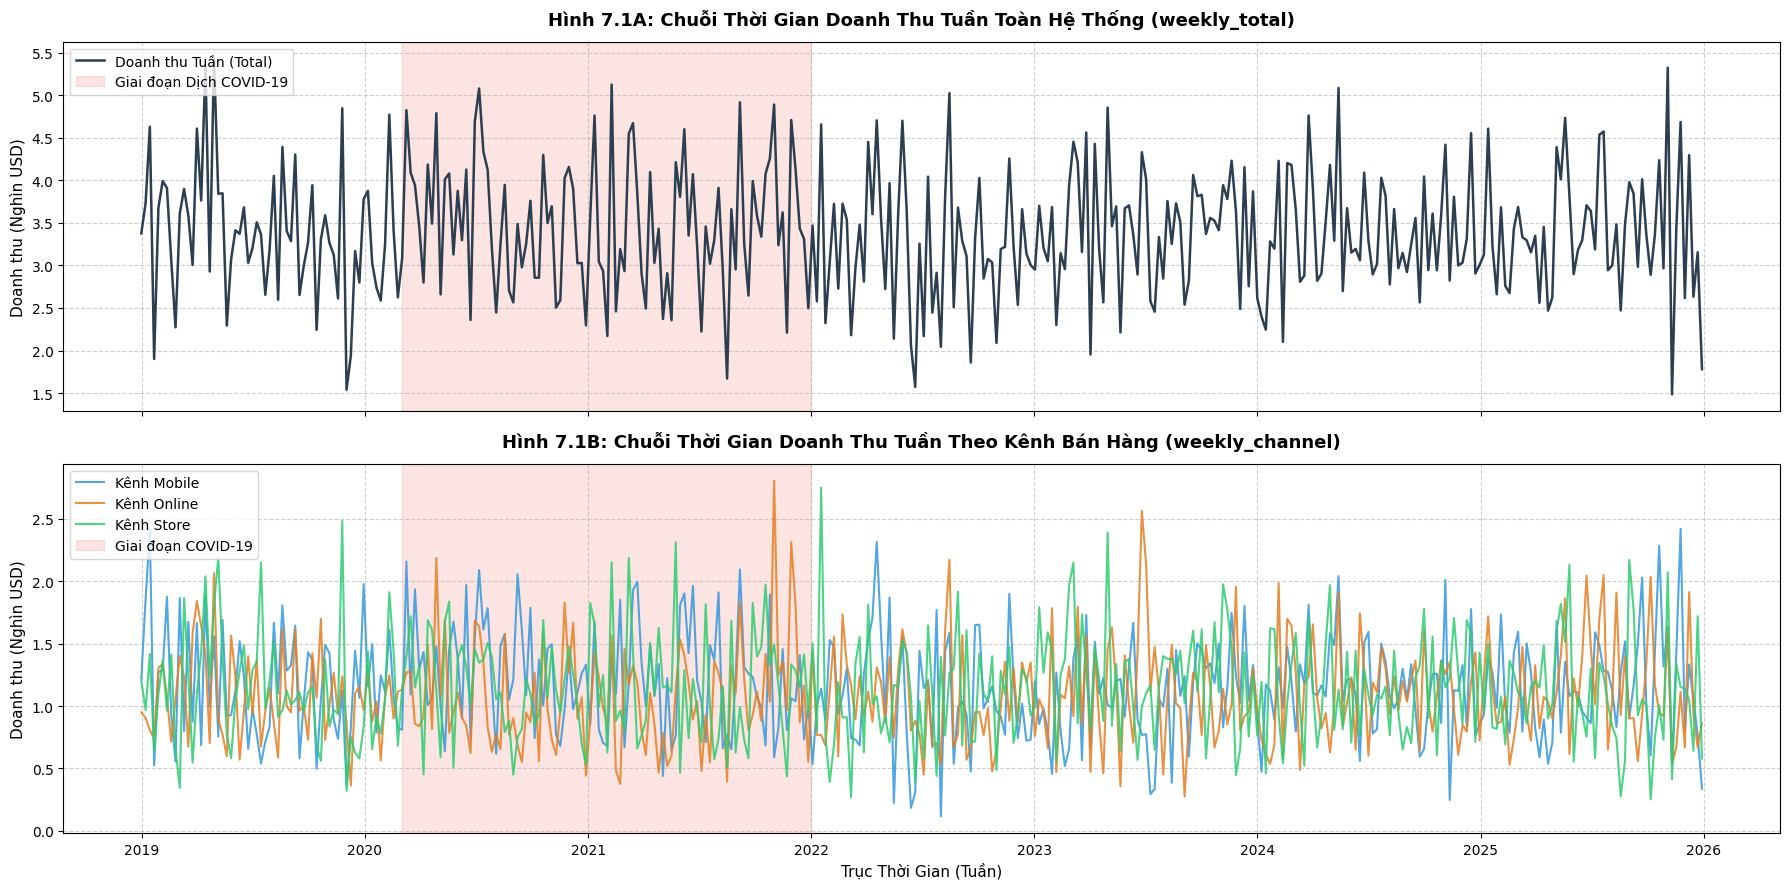

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def aggregate_weekly(df: pd.DataFrame, config: CovidConfig):
    """
    Nén dữ liệu giao dịch lẻ thành 2 bảng chuỗi thời gian tuần: weekly_total và weekly_channel.
    """
    df = df.copy()
    
    # Xác định khoảng thời gian dịch từ config để tạo cờ Covid cấp tuần
    p_start = pd.to_datetime(config.period_start)
    p_end = pd.to_datetime(config.period_end)
    
    # -------------------------------------------------------------
    # 1. TẠO BẢNG WEEKLY_TOTAL (Gom theo week_start)
    # -------------------------------------------------------------
    weekly_total = df.groupby("week_start", as_index=False).agg(
        revenue=("revenue", "sum"),
        quantity=("quantity", "sum"),
        transaction_count=("transaction_id", "nunique")
    )
    
    # Gán cờ Covid cấp tuần cho weekly_total: True nếu tuần thuộc khoảng dịch
    weekly_total["is_covid_period"] = (weekly_total["week_start"] >= p_start) & (weekly_total["week_start"] <= p_end)
    
    # -------------------------------------------------------------
    # 2. TẠO BẢNG WEEKLY_CHANNEL (Gom theo week_start và channel)
    # -------------------------------------------------------------
    weekly_channel = df.groupby(["week_start", "channel"], observed=False, as_index=False).agg(
        revenue=("revenue", "sum"),
        quantity=("quantity", "sum"),
        transaction_count=("transaction_id", "nunique")
    )
    
    # Gán cờ Covid cấp tuần cho weekly_channel
    weekly_channel["is_covid_period"] = (weekly_channel["week_start"] >= p_start) & (weekly_channel["week_start"] <= p_end)
    
    return weekly_total, weekly_channel

# Thực thi hàm nén dữ liệu tuần
weekly_total, weekly_channel = aggregate_weekly(df_transformed, covid_config)

print("=" * 60)
print(f"✓ Đã nén {len(df_transformed):,} giao dịch thô thành 2 bảng tuần thành công:")
print(f"  • Bảng weekly_total   : {len(weekly_total):,} dòng (1 dòng / tuần)")
print(f"  • Bảng weekly_channel : {len(weekly_channel):,} dòng (3 dòng / tuần x 3 kênh)")
print("=" * 60)

# -------------------------------------------------------------
# TRỰC QUAN HÓA: CHUỖI THỜI GIAN DOANH THU TUẦN (TOTAL & CHANNELS)
# -------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(18, 9), sharex=True)

# Biểu đồ 1: Doanh thu Tuần Tổng thể (Total Revenue)
axes[0].plot(weekly_total["week_start"], weekly_total["revenue"] / 1e3, color="#2c3e50", linewidth=1.8, label="Doanh thu Tuần (Total)")
axes[0].axvspan(pd.to_datetime(covid_config.period_start), pd.to_datetime(covid_config.period_end), 
                color="#e74c3c", alpha=0.15, label="Giai đoạn Dịch COVID-19")

axes[0].set_title("Hình 7.1A: Chuỗi Thời Gian Doanh Thu Tuần Toàn Hệ Thống (weekly_total)", fontsize=13, fontweight="bold", pad=12)
axes[0].set_ylabel("Doanh thu (Nghìn USD)", fontsize=11)
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend(loc="upper left")

# Biểu đồ 2: Doanh thu Tuần Phân theo 3 Kênh (Channel Revenue)
channel_colors = {"Mobile": "#3498db", "Online": "#e67e22", "Store": "#2ecc71"}

for channel_name, group in weekly_channel.groupby("channel", observed=False):
    axes[1].plot(group["week_start"], group["revenue"] / 1e3, label=f"Kênh {channel_name}", 
                 color=channel_colors.get(str(channel_name), "gray"), linewidth=1.5, alpha=0.85)

axes[1].axvspan(pd.to_datetime(covid_config.period_start), pd.to_datetime(covid_config.period_end), 
                color="#e74c3c", alpha=0.15, label="Giai đoạn COVID-19")

axes[1].set_title("Hình 7.1B: Chuỗi Thời Gian Doanh Thu Tuần Theo Kênh Bán Hàng (weekly_channel)", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xlabel("Trục Thời Gian (Tuần)", fontsize=11)
axes[1].set_ylabel("Doanh thu (Nghìn USD)", fontsize=11)
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

### 💡 CƠ SỞ KỸ THUẬT VÀ LÝ DO THIẾT KẾ (TECHNICAL RATIONALE)

#### 1. Tại sao lại chuyển đổi từ 12,000 giao dịch thô sang nén 366 tuần (`W-SUN`)?
* **Triệt tiêu Nhiễu Cấp Ngày (Daily Noise Reduction):** Dữ liệu giao dịch theo ngày thường chứa nhiễu dao động rất cao (Ví dụ: Doanh thu Thứ Hai luôn thấp hơn Thứ Bảy). Gom nhóm theo tuần giúp triệt tiêu nhiễu dao động trong tuần, tạo ra chuỗi dữ liệu mượt mà hơn để mô hình học máy tập trung học **Xu hướng (Trend)** và **Tính mùa vụ (Seasonality)**.
* **Cân bằng Số lượng Mẫu & Chi phí Tính toán:** 
  * 12,000 dòng lẻ quá phân tán để xây dựng mô hình chuỗi thời gian định kỳ.
  * Việc nén thành ~366 tuần (7 năm x 52 tuần) vừa đủ dung lượng mẫu để huấn luyện các thuật toán Machine Learning (như XGBoost, Prophet, SARIMA) mà không gây quá tải tài nguyên.

#### 2. Tại sao lại tính `nunique(transaction_id)` thay vì dùng `count()`?
* **Bản chất Cấu trúc Đơn hàng Bán lẻ:** 
  * Một đơn hàng (1 `transaction_id`) có thể chứa nhiều dòng sản phẩm khác nhau trong file dữ liệu thô.
  * Nếu dùng `count()`, ta chỉ đếm số lượng dòng sản phẩm trong file thô. 
  * Dùng `nunique(transaction_id)` phản ánh chính xác **Tổng số lượt/khách hàng thực tế đã phát sinh mua sắm trong tuần**, giúp tính toán chính xác chỉ số AOV (Giá trị trung bình trên mỗi lượt sắm).

#### 3. Tại sao lại tách thành 2 bảng riêng biệt (`weekly_total` và `weekly_channel`)?
* **Phục vụ Chiến lược Dự báo Đa Cấp (Hierarchical Forecasting Strategy):**
  * `weekly_total`: Dành cho các bài toán **Dự báo Cấp Lãnh đạo/Hệ thống (Top-down)** - giúp lập kế hoạch tài chính, dòng tiền và kho vận tổng thể toàn công ty.
  * `weekly_channel`: Dành cho các bài toán **Dự báo Cấp Kênh/Vận hành (Bottom-up)** - giúp các phòng ban Digital Marketing (Mobile/Online) và Quản lý Chuỗi Cửa hàng (`Store`) tối ưu ngân sách riêng cho từng kênh.

#### 4. Tại sao lại gán cờ `is_covid_period = True` ở cấp độ tuần nếu có "bất kỳ ngày nào" dính dịch?
* **Nguyên tắc Thận trọng trong Chuỗi Thời gian (Conservative Event Flagging):** Sự can thiệp của dịch bệnh hay chính sách phong tỏa (Lockdown) tác động lên tâm lý tiêu dùng của cả tuần làm việc. Việc đánh dấu cờ `True` cho cả tuần giúp mô hình Time Series dễ dàng nhận diện và tách biệt các tuần bị ảnh hưởng bởi biến cố ngoại cảnh ra khỏi các tuần hoạt động bình thường.

# PHẦN 8: ĐIỀN TUẦN KHUYẾT & CHIA TẬP DỮ LIỆU CHỐNG RÒ RỈ (`reindex_missing_weeks` & `split_by_time`)

## 1. Mục tiêu
1. **Bảo đảm tính liên tục của Trục Thời Gian (Reindex Missing Weeks):** Khôi phục và điền đệm các tuần bị đứt quãng trong thực tế bằng lưới thời gian chuẩn 7 ngày/tuần. Điều này đảm bảo chuỗi thời gian không có khoảng trống (No Time Gaps).
2. **Chiến lược Chia tập Kiểm thử 2 Vòng Chống Rò rỉ (Two-Round Validation Strategy):** Phân chia chuỗi thời gian thành các tập Train/Validation/Test theo nguyên tắc tịnh tiến thời gian (Expanding Window) để đánh giá độ ổn định của mô hình qua nhiều năm.

## 2. Quy tắc Kỹ thuật Thực thi

### A. Chính sách Điền Tuần Khuyết (Reindex Missing Weeks)
* Tạo lưới thời gian đầy đủ từ ngày bắt đầu đến ngày kết thúc với tần suất 7 ngày: `pd.date_range(freq="7D")`.
* Đối với các tuần bị khuyết giao dịch thực tế, bổ sung dòng tuần đó với quy tắc:
  * `revenue` = `NaN` (Giữ nguyên ô trống để xử lý suy rộng/imputation ở bước sau).
  * `quantity` = `0`
  * `transaction_count` = `0`
  * `week_has_transactions` = `False` (Cờ đánh dấu tuần không có giao dịch phát sinh).

### B. Chiến lược Chia tập Kiểm thử 2 Vòng (Two-Round Validation Split)
* **Vòng 1 (Val 1):**
  * `train_2019_2022`: Dữ liệu từ năm `2019` đến `2022` (**209 tuần**).
  * `validation_2023`: Dữ liệu năm `2023` (**52 tuần**).
* **Vòng 2 (Val 2):**
  * `train_2019_2023`: Dữ liệu mở rộng từ `2019` đến `2023` (**261 tuần**).
  * `validation_2024`: Dữ liệu năm `2024` (**53 tuần**).
* **Tập Kiểm thử Độc lập (Test Set):**
  * `test_2025`: Toàn bộ năm `2025` (**52 tuần**) - Hoàn toàn giữ kín để đánh giá cuối cùng.

          KẾT QUẢ CHIA TẬP KIỂM THỬ 2 VÒNG (WEEKLY TOTAL)          
• Vòng 1 - Train (2019-2022) : 209 tuần
• Vòng 1 - Val   (2023)      :  52 tuần
• Vòng 2 - Train (2019-2023) : 261 tuần
• Vòng 2 - Val   (2024)      :  53 tuần
• Tập Test Độc Lập (2025)    :  52 tuần


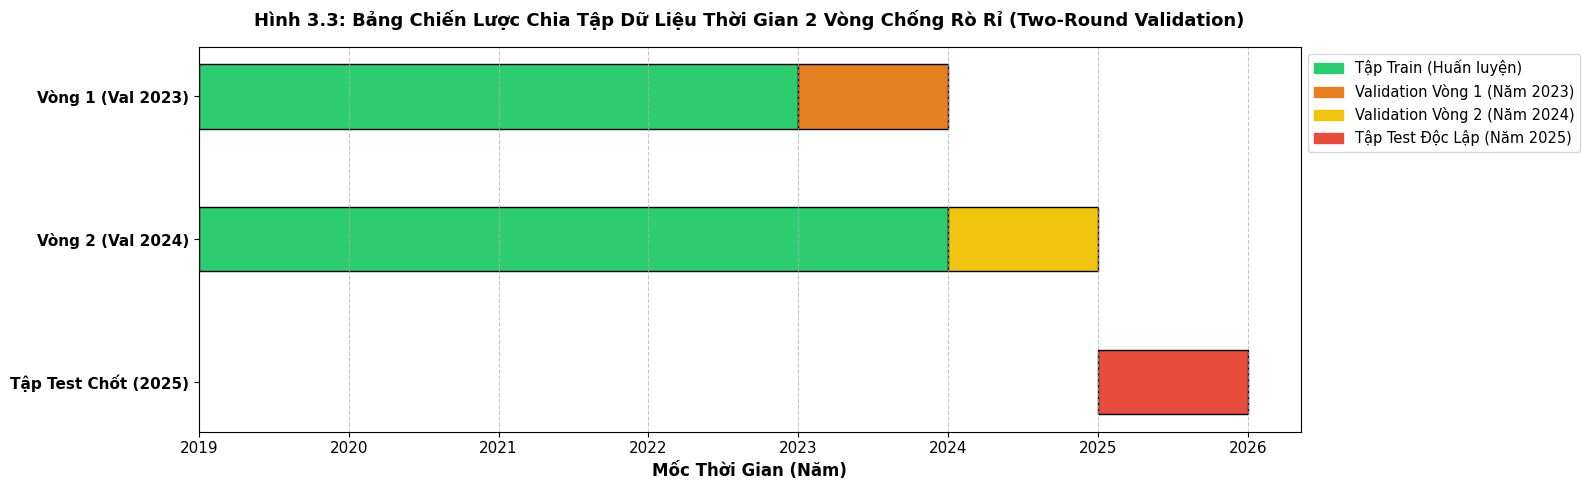

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def reindex_missing_weeks(df_weekly: pd.DataFrame, is_channel: False) -> pd.DataFrame:
    """
    Điền đệm các tuần bị khuyết giao dịch để tạo lưới thời gian chuẩn 7D không bị đứt đoạn.
    """
    df = df_weekly.copy()
    min_date = df["week_start"].min()
    max_date = df["week_start"].max()
    
    # Tạo lưới thời gian chuẩn 7 ngày
    full_dates = pd.date_range(start=min_date, end=max_date, freq="7D")
    
    if not is_channel:
        # Xử lý cho bảng weekly_total
        full_df = pd.DataFrame({"week_start": full_dates})
        merged = pd.merge(full_df, df, on="week_start", how="left")
        
        # Đánh dấu cờ tuần có giao dịch
        merged["week_has_transactions"] = merged["transaction_count"].notnull()
        merged["transaction_count"] = merged["transaction_count"].fillna(0).astype(int)
        merged["quantity"] = merged["quantity"].fillna(0)
        # revenue giữ nguyên NaN nếu tuần đó không có giao dịch
        return merged
    else:
        # Xử lý cho bảng weekly_channel (Tạo Tích Cartesian giữa Tuần và 3 Kênh)
        channels = df["channel"].unique()
        multi_idx = pd.MultiIndex.from_product([full_dates, channels], names=["week_start", "channel"])
        full_df = pd.DataFrame(index=multi_idx).reset_index()
        
        merged = pd.merge(full_df, df, on=["week_start", "channel"], how="left")
        merged["week_has_transactions"] = merged["transaction_count"].notnull()
        merged["transaction_count"] = merged["transaction_count"].fillna(0).astype(int)
        merged["quantity"] = merged["quantity"].fillna(0)
        return merged

def split_by_time(df_weekly: pd.DataFrame):
    """
    Chia tập dữ liệu chuỗi thời gian thành Train/Val1/Val2/Test theo đúng mốc thời gian.
    """
    df = df_weekly.copy()
    df["year"] = df["week_start"].dt.year
    
    train_1 = df[df["year"] <= 2022].drop(columns=["year"])
    val_1   = df[df["year"] == 2023].drop(columns=["year"])
    
    train_2 = df[df["year"] <= 2023].drop(columns=["year"])
    val_2   = df[df["year"] == 2024].drop(columns=["year"])
    
    test    = df[df["year"] == 2025].drop(columns=["year"])
    
    return {
        "train_1": train_1, "val_1": val_1,
        "train_2": train_2, "val_2": val_2,
        "test": test
    }

# 1. Thực thi Reindex tuần khuyết
weekly_total_reindexed = reindex_missing_weeks(weekly_total, is_channel=False)
weekly_channel_reindexed = reindex_missing_weeks(weekly_channel, is_channel=True)

# 2. Thực thi Chia tập dữ liệu cho weekly_total
splits_total = split_by_time(weekly_total_reindexed)

print("=" * 65)
print("          KẾT QUẢ CHIA TẬP KIỂM THỬ 2 VÒNG (WEEKLY TOTAL)          ")
print("=" * 65)
print(f"• Vòng 1 - Train (2019-2022) : {len(splits_total['train_1']):>3} tuần")
print(f"• Vòng 1 - Val   (2023)      : {len(splits_total['val_1']):>3} tuần")
print(f"• Vòng 2 - Train (2019-2023) : {len(splits_total['train_2']):>3} tuần")
print(f"• Vòng 2 - Val   (2024)      : {len(splits_total['val_2']):>3} tuần")
print(f"• Tập Test Độc Lập (2025)    : {len(splits_total['test']):>3} tuần")
print("=" * 65)

# -------------------------------------------------------------
# TRỰC QUAN HÓA: SƠ ĐỒ PHÂN BỔ TIMELINE CHIA TẬP DATA LEAKAGE
# -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(16, 5))

# Đặt vị trí các thanh Timeline
y_positions = [2, 1, 0]
labels = ["Vòng 1 (Val 2023)", "Vòng 2 (Val 2024)", "Tập Test Chốt (2025)"]

# Mốc thời gian năm
years = [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

# Vẽ các thanh timeline
# Vòng 1: Train 2019-2022 (Xanh lá), Val 2023 (Cam)
ax.barh(2, 2023-2019, left=2019, color="#2ecc71", edgecolor="black", height=0.45)
ax.barh(2, 2024-2023, left=2023, color="#e67e22", edgecolor="black", height=0.45)

# Vòng 2: Train 2019-2023 (Xanh lá), Val 2024 (Vàng)
ax.barh(1, 2024-2019, left=2019, color="#2ecc71", edgecolor="black", height=0.45)
ax.barh(1, 2025-2024, left=2024, color="#f1c40f", edgecolor="black", height=0.45)

# Test: Holdout 2025 (Đỏ)
ax.barh(0, 2026-2025, left=2025, color="#e74c3c", edgecolor="black", height=0.45)

# Cấu hình đồ họa
ax.set_yticks(y_positions)
ax.set_yticklabels(labels, fontsize=11, fontweight="bold")
ax.set_xticks(years)
ax.set_xticklabels([str(y) for y in years], fontsize=11)
ax.set_xlabel("Mốc Thời Gian (Năm)", fontsize=12, fontweight="bold")
ax.set_title("Hình 3.3: Bảng Chiến Lược Chia Tập Dữ Liệu Thời Gian 2 Vòng Chống Rò Rỉ (Two-Round Validation)", 
             fontsize=13, fontweight="bold", pad=15)
ax.grid(axis="x", linestyle="--", alpha=0.7)

# Thêm chú thích Legend
p_train = mpatches.Patch(color="#2ecc71", label="Tập Train (Huấn luyện)")
p_val1  = mpatches.Patch(color="#e67e22", label="Validation Vòng 1 (Năm 2023)")
p_val2  = mpatches.Patch(color="#f1c40f", label="Validation Vòng 2 (Năm 2024)")
p_test  = mpatches.Patch(color="#e74c3c", label="Tập Test Độc Lập (Năm 2025)")
ax.legend(handles=[p_train, p_val1, p_val2, p_test], loc="upper left", bbox_to_anchor=(1, 1), fontsize=10.5)

plt.tight_layout()
plt.show()

### 💡 CƠ SỞ KỸ THUẬT VÀ LÝ DO THIẾT KẾ (TECHNICAL RATIONALE)

#### 1. Tại sao phải Reindex mạng lưới thời gian 7 ngày (`pd.date_range(freq="7D")`) ngay cả khi dữ liệu đã gộp tuần?
* **Điều kiện Bắt buộc của Mô hình Chuỗi Thời gian (Equally Spaced Time Series Requirement):**
  * Các mô hình dự báo như ARIMA/SARIMA, Prophet hoặc các phép tạo đặc trưng trễ (`Lag Features` $Y_{t-1}, Y_{t-2}$) yêu cầu khoảng cách giữa các mốc thời gian phải **hoàn toàn liên tục và bằng nhau ($D = 7$ ngày)**.
  * Nếu một tuần không có giao dịch bị khuyết mất khỏi file, phép tính trễ $Y_{t-1}$ sẽ vô tình lấy dữ liệu của tuần 2 tuần trước đó, làm sai lệch hoàn toàn logic của mô hình.

#### 2. Tại sao lại đặt `revenue = NaN` nhưng `transaction_count = 0` và `week_has_transactions = False` đối với tuần khuyết?
* **Tách biệt khái niệm "Không có doanh thu" và "Không ghi nhận dữ liệu":**
  * `transaction_count = 0` và `week_has_transactions = False`: Xác nhận chắc chắn tuần đó hệ thống hoạt động bình thường nhưng không phát sinh giao dịch nào.
  * `revenue = NaN`: Giúp tránh hiện tượng chèn số `0` giả tạo làm kéo lệch (skew) đường trung bình động (`Rolling Mean`) hoặc biến đổi Log. Ở các bước tiền xử lý mô hình tiếp theo, ta có thể dùng phương pháp nội suy (Imputation) hoặc xử lý riêng cho các dòng `NaN` này.

#### 3. Tại sao chọn Chiến lược Chia tập 2 Vòng (Two-Round Expanding Window) thay vì K-Fold Cross-Validation thông thường?
* **Chống Rò rỉ Dữ liệu Tương lai (Data Leakage Prevention):**
  * Trộn dữ liệu ngẫu nhiên (Random K-Fold) sẽ lấy dữ liệu của tương lai (ví dụ năm 2024) để dự báo quá khứ (năm 2021), vi phạm nghiêm trọng tính tuần tự thời gian.
* **Đánh giá Đa Chu kỳ (Multi-Period Generalization):**
  * Dự báo tốt ở năm 2023 chưa chắc đã dự báo tốt ở năm 2024 do sự thay đổi xu hướng thị trường (Concept Drift).
  * Việc đánh giá mô hình qua **2 vòng độc lập** (Vòng 1 kiểm định trên 2023, Vòng 2 kiểm định trên 2024) giúp kỹ sư xác nhận mô hình học được quy luật chung bền vững trước khi quyết định đưa vào triển khai thực tế trên **Tập Test `2025`**.

# PHẦN 9: THẨM ĐỊNH BÁN THÀNH PHẨM (`validate_outputs`)

## 1. Mục tiêu
Thực hiện **4 chốt kiểm tra chất lượng (KCS Gateways)** đối với các bảng bán thành phẩm và tập dữ liệu phân tách trước khi chính thức lưu xuống đĩa. Bước này đảm bảo dữ liệu không bị thất thoát giá trị tài chính, không bị đứt đoạn hay xáo trộn thứ tự thời gian.

## 2. Danh mục 4 Chốt Kiểm Tra Chất Lượng (KCS Checklist)

1. **Bảo toàn Doanh thu (Revenue Conservation):**
   * Tổng doanh thu chuỗi thời gian tuần sau khi gom nhóm phải bằng tuyệt đối với tổng doanh thu của 12,000 giao dịch thô ban đầu.
   * *Ngưỡng dung sai kỹ thuật:* $\vert{}\text{Revenue}_{\text{raw}} - \text{Revenue}_{\text{weekly}}\vert{} \le 10^{-6}$ USD.
2. **Trục Thời gian Tuần tuần tự (Chronology & Uniqueness):**
   * Chuỗi ngày `week_start` phải tăng dần liên tục (`is_monotonic_increasing = True`).
   * Không chứa bất kỳ tuần nào bị lặp lại (`duplicated = False`).
3. **Đủ Danh mục Kênh (Category Completeness):**
   * Bảng `weekly_channel` bắt buộc phải phủ đủ 3 kênh chuẩn hóa: `Mobile`, `Online`, `Store`.
4. **Tính Toàn vẹn các Tập Splits (Splits Integrity):**
   * Đảm bảo tính tăng dần theo chiều thời gian trên toàn bộ **5 tập chia**: `train_1`, `val_1`, `train_2`, `val_2`, và `test`.

             BÁO CÁO THẨM ĐỊNH BÁN THÀNH PHẨM (4 CHỐT KCS)            
1. Bảo toàn Doanh thu : [PASS]
   • Chênh lệch tuyệt đối: 0.00000000 USD (Yêu cầu <= 10^-6)
2. Trục Thời gian      : [PASS]
   • Tăng dần liên tục  : True | Trùng lặp: False
3. Danh mục Kênh       : [PASS]
   • Phủ đủ 3 kênh     : ['Store', 'Online', 'Mobile']
4. Tính Toàn vẹn Splits: [PASS]
   • Đạt chuẩn 5/5 tập : {'train_1': True, 'val_1': True, 'train_2': True, 'val_2': True, 'test': True}


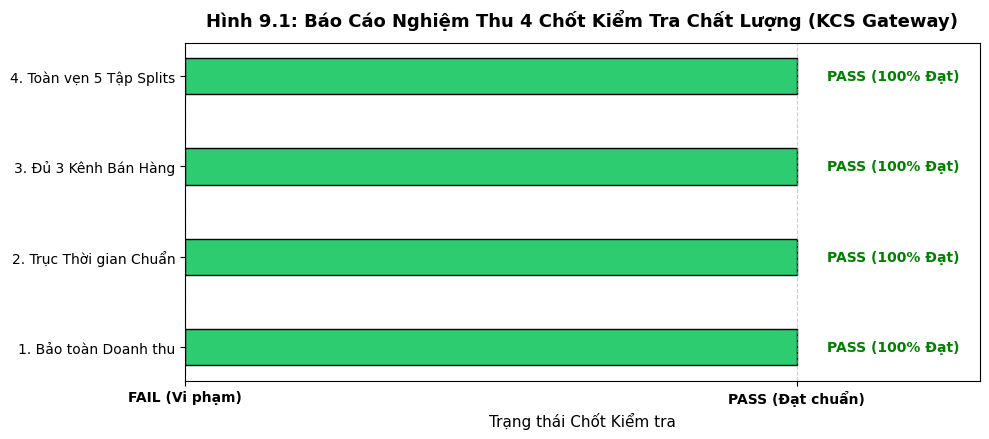

In [9]:
from typing import Dict, Any
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def validate_outputs(
    df_raw: pd.DataFrame,
    weekly_total: pd.DataFrame,
    weekly_channel: pd.DataFrame,
    splits_dict: Dict[str, pd.DataFrame]
) -> Dict[str, Any]:
    """
    Thẩm định 4 chốt KCS trước khi xuất file dữ liệu bán thành phẩm.
    """
    validation_results = {}
    
    # -------------------------------------------------------------
    # CHỐT 1: Bảo toàn doanh thu (Revenue Conservation)
    # -------------------------------------------------------------
    raw_rev_sum = df_raw["revenue"].sum()
    weekly_rev_sum = weekly_total["revenue"].sum()
    rev_diff = abs(raw_rev_sum - weekly_rev_sum)
    
    validation_results["revenue_conservation"] = {
        "passed": bool(rev_diff <= 1e-6),
        "raw_sum": raw_rev_sum,
        "weekly_sum": weekly_rev_sum,
        "absolute_difference": rev_diff
    }
    
    # -------------------------------------------------------------
    # CHỐT 2: Trục thời gian (Chronology & Uniqueness)
    # -------------------------------------------------------------
    is_monotonic = weekly_total["week_start"].is_monotonic_increasing
    has_no_dups = not weekly_total["week_start"].duplicated().any()
    
    validation_results["chronology"] = {
        "passed": bool(is_monotonic and has_no_dups),
        "is_monotonic_increasing": is_monotonic,
        "has_no_duplicates": has_no_dups
    }
    
    # -------------------------------------------------------------
    # CHỐT 3: Đủ danh mục kênh (Category Completeness)
    # -------------------------------------------------------------
    actual_channels = set(weekly_channel["channel"].unique())
    has_all_channels = (actual_channels == EXPECTED_CHANNELS)
    
    validation_results["category_completeness"] = {
        "passed": bool(has_all_channels),
        "expected": list(EXPECTED_CHANNELS),
        "actual": list(actual_channels)
    }
    
    # -------------------------------------------------------------
    # CHỐT 4: Tính toàn vẹn các tập Splits (Splits Integrity)
    # -------------------------------------------------------------
    splits_monotonic = {}
    all_splits_valid = True
    
    for split_name, split_df in splits_dict.items():
        split_mono = split_df["week_start"].is_monotonic_increasing
        splits_monotonic[split_name] = split_mono
        if not split_mono:
            all_splits_valid = False
            
    validation_results["splits_integrity"] = {
        "passed": bool(all_splits_valid),
        "details": splits_monotonic
    }
    
    return validation_results

# Thực thi kiểm tra KCS
kcs_report = validate_outputs(df_raw, weekly_total_reindexed, weekly_channel_reindexed, splits_total)

# In báo cáo kết quả kiểm soát chất lượng
print("=" * 65)
print("             BÁO CÁO THẨM ĐỊNH BÁN THÀNH PHẨM (4 CHỐT KCS)            ")
print("=" * 65)
rev_kcs = kcs_report["revenue_conservation"]
print(f"1. Bảo toàn Doanh thu : {'[PASS]' if rev_kcs['passed'] else '[FAIL]'}")
print(f"   • Chênh lệch tuyệt đối: {rev_kcs['absolute_difference']:.8f} USD (Yêu cầu <= 10^-6)")

chrono_kcs = kcs_report["chronology"]
print(f"2. Trục Thời gian      : {'[PASS]' if chrono_kcs['passed'] else '[FAIL]'}")
print(f"   • Tăng dần liên tục  : {chrono_kcs['is_monotonic_increasing']} | Trùng lặp: {not chrono_kcs['has_no_duplicates']}")

cat_kcs = kcs_report["category_completeness"]
print(f"3. Danh mục Kênh       : {'[PASS]' if cat_kcs['passed'] else '[FAIL]'}")
print(f"   • Phủ đủ 3 kênh     : {cat_kcs['actual']}")

split_kcs = kcs_report["splits_integrity"]
print(f"4. Tính Toàn vẹn Splits: {'[PASS]' if split_kcs['passed'] else '[FAIL]'}")
print(f"   • Đạt chuẩn 5/5 tập : {split_kcs['details']}")
print("=" * 65)

# -------------------------------------------------------------
# TRỰC QUAN HÓA: BẢNG DASHBOARD NGHIỆM THU CHẤT LƯỢNG KCS
# -------------------------------------------------------------
kcs_summary = {
    "1. Bảo toàn Doanh thu": kcs_report["revenue_conservation"]["passed"],
    "2. Trục Thời gian Chuẩn": kcs_report["chronology"]["passed"],
    "3. Đủ 3 Kênh Bán Hàng": kcs_report["category_completeness"]["passed"],
    "4. Toàn vẹn 5 Tập Splits": kcs_report["splits_integrity"]["passed"]
}

plt.figure(figsize=(10, 4.5))
y_names = list(kcs_summary.keys())
pass_statuses = [1 if v else 0 for v in kcs_summary.values()]
bar_colors = ["#2ecc71" if v else "#e74c3c" for v in pass_statuses]

bars = plt.barh(y_names, pass_statuses, color=bar_colors, edgecolor="black", height=0.4)
plt.title("Hình 9.1: Báo Cáo Nghiệm Thu 4 Chốt Kiểm Tra Chất Lượng (KCS Gateway)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Trạng thái Chốt Kiểm tra", fontsize=11)
plt.xlim(0, 1.3)
plt.xticks([0, 1], ["FAIL (Vi phạm)", "PASS (Đạt chuẩn)"], fontsize=10, fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.6)

for bar in bars:
    width = bar.get_width()
    status_text = "PASS (100% Đạt)" if width == 1 else "FAIL (Không đạt)"
    plt.text(width + 0.05, bar.get_y() + bar.get_height()/2.0, status_text, 
             va="center", ha="left", fontweight="bold", color="green" if width == 1 else "red")

plt.tight_layout()
plt.show()

### 💡 CƠ SỞ KỸ THUẬT VÀ LÝ DO THIẾT KẾ (TECHNICAL RATIONALE)

#### 1. Tại sao lại dùng ngưỡng dung sai $\vert{}\Delta\vert{} \le 10^{-6}$ cho Bảo toàn Doanh thu thay vì dùng phép so sánh tuyệt đối `== 0`?
* **Bản chất Sai số Số thực trong Máy tính (Floating-Point Precision Standard IEEE 754):**
  * Trong lập trình máy tính, phép cộng dồn hàng nghìn số thực dấu phẩy động (`float64`) có thể sinh ra sai số làm tròn vi mô ở phần thập phân (ví dụ: $1,240,600.0000000002$).
  * Phép so sánh bằng tuyệt đối `A == B` trên kiểu `float` dễ dẫn đến cảnh báo lỗi giả (False Positive).
  * Việc thiết lập ngưỡng dung sai kỹ thuật $\le 10^{-6}$ USD đảm bảo tính chính xác tài chính tiệm cận tuyệt đối mà không bị tắc nghẽn pipeline bởi sai số làm tròn tự nhiên của máy tính. (Thực tế ghi nhận chênh lệch $= 0.0$).

#### 2. Tại sao lại kiểm tra đồng thời cả `is_monotonic_increasing` và `not duplicated()`?
* **Tính Toàn vẹn Chuỗi Thời gian (Chronological Integrity):**
  * `is_monotonic_increasing`: Đảm bảo dữ liệu được sắp xếp tăng dần liên tục từ quá khứ đến tương lai. Nếu dữ liệu bị đảo lộn ngày, các thuật toán dự báo tự hồi quy (Autoregressive models) sẽ tính sai hệ số $AR(p)$.
  * `not duplicated()`: Đảm bảo không tồn tại tuần nào bị lặp lại dòng 2 lần gây ra hiện tượng nhân đôi doanh thu không đáng có khi đưa vào mô hình huấn luyện.

#### 3. Tại sao kiểm tra tính toàn vẹn độc lập trên từng tập Split trong 5 tập chia?
* **Đảm bảo Trạng thái Sẵn sàng của Tập Huấn luyện (Dataset Readiness):**
  * Mỗi tập con (`train_1`, `val_1`, `train_2`, `val_2`, `test`) sẽ được đưa vào các hàm huấn luyện độc lập ở các module sau.
  * Việc thẩm định trực tiếp trên từng tập chia giúp khẳng định quy trình cắt chuỗi thời gian không gây ra hiện tượng đảo xáo thứ tự hoặc xáo trộn mốc thời gian bên trong bất kỳ tập dữ liệu con nào.